In [2]:
from Bio import SeqIO
import re
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt

In [6]:
colnames = ["chr", "source", "feature", "start", "end", "score", "strand", "frame", "attribute"]
gtf = pd.read_table("../../NV2g.20240221.gtf", names = colnames)
print(gtf.shape)
gtf.head()

(564871, 9)


,chr,source,feature,start,end,score,strand,frame,attribute
0,chrUn3,transdecoder,transcript,1176,35911,.,+,.,"transcript_id ""NV2t025931001.1""; gene_id ""NV2g..."
1,chrUn3,transdecoder,exon,1176,35911,.,+,.,"transcript_id ""NV2t025931001.1""; gene_id ""NV2g..."
2,chrUn3,transdecoder,CDS,19069,20280,.,+,0,"transcript_id ""NV2t025931001.1""; gene_id ""NV2g..."
3,chrUn2,transdecoder,transcript,1353,3171,.,-,.,"transcript_id ""NV2t025877001.1""; gene_id ""NV2g..."
4,chrUn2,transdecoder,exon,1353,1582,.,-,.,"transcript_id ""NV2t025877001.1""; gene_id ""NV2g..."


In [9]:
gtf_dedup = gtf.drop_duplicates(subset=["chr", "start", "end"])
gtf_dedup.shape

(262048, 9)

In [2]:
#read nematostella genome
genome = []
with open("../Nvec200.fasta") as handle:
    for record in SeqIO.parse(handle, "fasta"):
        genome.append(record)

genome

[SeqRecord(seq=Seq('ATACCCCTCTCCCCTGCACTGGATAGATACGACATGTATACCCCTTCCTCTGTA...AAA'), id='chr1', name='chr1', description='chr1', dbxrefs=[]),
 SeqRecord(seq=Seq('GCAGGTGTCATTCTTTGCTGGGCAAAGCTGACAGTCATGCTTCTGTTTGCCACA...TAA'), id='chr2', name='chr2', description='chr2', dbxrefs=[]),
 SeqRecord(seq=Seq('TAAACTGTTACCTCTCCCCTCCACCAGTTAAGCATTCTATGTAGGCTTCCCTGT...AAA'), id='chr3', name='chr3', description='chr3', dbxrefs=[]),
 SeqRecord(seq=Seq('CCCTGTGTTATTTTCGGGAAAAATACACCTGTACATGGCCCGGGTAATAGGAAC...ATT'), id='chr4', name='chr4', description='chr4', dbxrefs=[]),
 SeqRecord(seq=Seq('GGTTGTTACAAATCCGGTTGATTGTTGTTACAAATCCGGCTGTTGTTACATATC...TGG'), id='chr5', name='chr5', description='chr5', dbxrefs=[]),
 SeqRecord(seq=Seq('TGGCTTTTTCTTAAAAATTGAAAAACATTCTGGAAAATATCATTATCAATTGGT...ACT'), id='chr6', name='chr6', description='chr6', dbxrefs=[]),
 SeqRecord(seq=Seq('GATGCACAGTCCCCAATGTAGAGAACCAGGTTTATTACACCTCTGAAAAAAATC...AGA'), id='chr7', name='chr7', description='chr7', dbxrefs=[]),
 SeqRecord(se

In [3]:
str(genome[0].seq)[0:20]

'ATACCCCTCTCCCCTGCACT'

In [4]:
genome[0].name

'chr1'

In [5]:
def find_motif_positions(motif, ref):
    #assumes ref is a SeqRecord object; we convert it to a string for using RegularExpressions
    ref_string = str(ref.seq)
    return [m.start() for m in re.finditer(motif, ref_string)]

In [6]:
find_motif_positions("AATAAAAAAA", genome[0])

[24366,
 30314,
 33048,
 40746,
 56781,
 66168,
 104321,
 108008,
 122299,
 131768,
 226995,
 233453,
 297663,
 322660,
 367926,
 375428,
 520387,
 520779,
 724233,
 745400,
 775986,
 934397,
 1002676,
 1011395,
 1155691,
 1163600,
 1176390,
 1213786,
 1224620,
 1234211,
 1258509,
 1270929,
 1293529,
 1309785,
 1363156,
 1373955,
 1426485,
 1427694,
 1469562,
 1517108,
 1518164,
 1527629,
 1555301,
 1564313,
 1604171,
 1616099,
 1622312,
 1659822,
 1678888,
 1705084,
 1722834,
 1779665,
 1800027,
 1837920,
 1852794,
 1859383,
 1925516,
 1975780,
 1979852,
 1999837,
 2064846,
 2106271,
 2122235,
 2123650,
 2143366,
 2159036,
 2208489,
 2217054,
 2249533,
 2335933,
 2366065,
 2426548,
 2441582,
 2442629,
 2456751,
 2575304,
 2576704,
 2637210,
 2639234,
 2643390,
 2664060,
 2684492,
 2690794,
 2715515,
 2724155,
 2775084,
 2782569,
 2798347,
 2836920,
 2841327,
 2841347,
 2878224,
 2891970,
 2901986,
 2905919,
 2911010,
 2943848,
 2944531,
 2954378,
 2992153,
 2996737,
 2999579,
 3010256

In [7]:
colnames = ["chr", "source", "feature", "start", "end", "score", "strand", "frame", "attribute"]
gtf = pd.read_table("../../NV2g.20240221.gtf", names = colnames)
gtf.head()

,chr,source,feature,start,end,score,strand,frame,attribute
0,chrUn3,transdecoder,transcript,1176,35911,.,+,.,"transcript_id ""NV2t025931001.1""; gene_id ""NV2g..."
1,chrUn3,transdecoder,exon,1176,35911,.,+,.,"transcript_id ""NV2t025931001.1""; gene_id ""NV2g..."
2,chrUn3,transdecoder,CDS,19069,20280,.,+,0,"transcript_id ""NV2t025931001.1""; gene_id ""NV2g..."
3,chrUn2,transdecoder,transcript,1353,3171,.,-,.,"transcript_id ""NV2t025877001.1""; gene_id ""NV2g..."
4,chrUn2,transdecoder,exon,1353,1582,.,-,.,"transcript_id ""NV2t025877001.1""; gene_id ""NV2g..."


In [14]:
def find_closest_downstream(pos, chr, within = 10000):
    """
    Given a chromosomal position and a chromosome name, this function will find the closest features downstream of the position
    within a certain radius; that is, having a higher positional start value than the position parameter. 
    Objects are returned as a pandas dataframe.
    - pos: integer position for which you want to find downstream object(s).
    - chr: name of the chromosome on which you want to find object(s).
    - within (default 10000): integer number for the distance from start site you wish to examine.
    """
    df_filt = gtf[gtf["chr"] == chr]
    df_filt = df_filt[df_filt["start"] >= pos]
    df_filt = df_filt[df_filt["start"] <= (pos + within)]

    #the GTF is NOT sorted by default, so we'll sort the GTF subset
    df_filt_sort = df_filt.sort_values(by=["start", "end"])
    return df_filt_sort

In [45]:
find_closest_downstream(1155691, "chr1").shape

(19, 9)

In [20]:
def find_closest_upstream(pos, chr, within = 10000):
    """
    Given a chromosomal position and a chromosome name, this function will find the closest features downstream of the position
    within a certain radius; that is, having a higher positional start value than the position parameter. 
    Objects are returned as a pandas dataframe.
    - pos: integer position for which you want to find downstream object(s).
    - chr: name of the chromosome on which you want to find object(s).
    - within (default 10000): integer number for the distance from start site you wish to examine.
    """
    df_filt = gtf[gtf["chr"] == chr]
    df_filt = df_filt[df_filt["start"] <= pos]
    df_filt = df_filt[df_filt["start"] >= (pos - within)]

    #the GTF is NOT sorted by default, so we'll sort the GTF subset
    df_filt_sort = df_filt.sort_values(by=["start", "end"], ascending=False)
    return df_filt_sort

In [21]:
find_closest_upstream(1155691, "chr1")

,chr,source,feature,start,end,score,strand,frame,attribute
456151,chr1,transdecoder,transcript,1154042,1156700,.,-,.,"transcript_id ""NV2t000089001.1""; gene_id ""NV2g..."
456152,chr1,transdecoder,exon,1154042,1156700,.,-,.,"transcript_id ""NV2t000089001.1""; gene_id ""NV2g..."
456120,chr1,transdecoder,exon,1152217,1152647,.,-,.,"transcript_id ""NV2t000088001.1""; gene_id ""NV2g..."
456119,chr1,transdecoder,exon,1151047,1151171,.,-,.,"transcript_id ""NV2t000088001.1""; gene_id ""NV2g..."
456150,chr1,transdecoder,CDS,1151047,1151105,.,-,0,"transcript_id ""NV2t000088001.1""; gene_id ""NV2g..."
456118,chr1,transdecoder,exon,1150642,1150682,.,-,.,"transcript_id ""NV2t000088001.1""; gene_id ""NV2g..."
456149,chr1,transdecoder,CDS,1150642,1150682,.,-,1,"transcript_id ""NV2t000088001.1""; gene_id ""NV2g..."
456117,chr1,transdecoder,exon,1150431,1150536,.,-,.,"transcript_id ""NV2t000088001.1""; gene_id ""NV2g..."
456148,chr1,transdecoder,CDS,1150431,1150536,.,-,2,"transcript_id ""NV2t000088001.1""; gene_id ""NV2g..."
456116,chr1,transdecoder,exon,1150210,1150353,.,-,.,"transcript_id ""NV2t000088001.1""; gene_id ""NV2g..."


In [44]:
upstream_test = find_closest_upstream(1155691, "chr1")
print(upstream_test.iloc[1]["attribute"][42:-2])
print(upstream_test.shape)

NV2g000089000.1
(35, 9)


In [23]:
colnames_go = ["id", "type", "term_id", "term_name", "description", "source"]
goterms = pd.read_table("../../NV2g.20240221.GO.tsv", names=colnames_go)
goterms.head()

,id,type,term_id,term_name,description,source
0,NV2g000003000.1,cellular_component,GO:0005777,peroxisome,A small organelle enclosed by a single membran...,InterPro
1,NV2g000005000.1,cellular_component,GO:0005777,peroxisome,A small organelle enclosed by a single membran...,InterPro
2,NV2g000005000.1,cellular_component,GO:0005777,peroxisome,A small organelle enclosed by a single membran...,OMA
3,NV2g000006000.1,cellular_component,GO:0005777,peroxisome,A small organelle enclosed by a single membran...,InterPro
4,NV2g000007000.1,biological_process,GO:0035269,protein O-linked mannosylation,The transfer of mannose from dolichyl activate...,OMA


In [75]:
def find_goterms_onepos(pos, chr, within=10000):
    """
    Finds the GO terms linked to one specific position on a character. Meant to be used as a helper function.
    """
    objs_upstream = find_closest_upstream(pos, chr, within=within)
    objs_downstream = find_closest_downstream(pos, chr, within=within)

    all_objs = pd.concat([objs_downstream, objs_upstream])

    term_ids = {}
    term_names = {}
    for i in range(len(all_objs)):
        current_id = all_objs.iloc[i]["attribute"][42:-2]
        current_row = goterms[goterms["id"] == current_id]

        #if there is none: keep going
        if len(current_row) <= 0:
            continue
        else:
            current_row = current_row.iloc[0]

        if str(current_row["term_id"]) in term_ids:
            term_ids[str(current_row["term_id"])] += 1
        else:
            term_ids[str(current_row["term_id"])] = 1

        if str(current_row["term_name"]) in term_names:
            term_names[str(current_row["term_name"])] += 1
        else:
            term_names[str(current_row["term_name"])] = 1
    return term_ids, term_names

In [76]:
find_goterms_onepos(1155691, "chr1")

({'GO:0006508': 33}, {'proteolysis': 33})

In [79]:
def find_goterms_onechr(positions, chr, within=10000):
    """ 
    Finds the GO terms associated with all the motif positions on a single chromosome. Also can meant to be used as a helper function.
    IMPORTANT: This function may count duplicates. 
    TODO: fix this function and previous helper ones so that duplicates are not counted. 
    """
    term_ids = {}
    term_names = {}
    for p in positions:
        #print(p)
        current_ids, current_names = find_goterms_onepos(p, chr, within=within)
        for key in current_ids:
            if key in term_ids:
                term_ids[key] += current_ids[key]
            else:
                term_ids[key] = current_ids[key]

        for name in current_names:
            if name in term_names:
                term_names[name] += current_names[name]
            else:
                term_names[name] = current_names[name]
    return term_ids, term_names

In [80]:
positions_test = find_motif_positions("AATAAAAAAA", genome[0])
find_goterms_onechr(positions_test, "chr1", within=1000)

({'GO:0005777': 18,
  'GO:0006364': 28,
  'GO:0006520': 15,
  'GO:0006468': 138,
  'GO:0000077': 12,
  'GO:0006457': 6,
  'GO:0008061': 4,
  'GO:0005737': 54,
  'GO:0007186': 14,
  'GO:0055085': 71,
  'GO:0005615': 26,
  'GO:0016020': 41,
  'GO:0005829': 6,
  'GO:0006405': 19,
  'GO:0007264': 8,
  'GO:0055088': 13,
  'GO:0008021': 4,
  'GO:0071277': 18,
  'GO:0006672': 12,
  'GO:0009952': 8,
  'GO:0000301': 4,
  'GO:0005515': 75,
  'GO:0090481': 2,
  'GO:0051260': 9,
  'GO:0030117': 28,
  'GO:0035556': 48,
  'GO:0016491': 21,
  'GO:0090630': 18,
  'GO:0019878': 1,
  'GO:0006355': 94,
  'GO:0034220': 34,
  'GO:0042073': 2,
  'GO:0009116': 16,
  'GO:0000266': 24,
  'GO:0008277': 8,
  'GO:0061617': 8,
  'GO:0005524': 48,
  'GO:0005783': 16,
  'GO:0051966': 1,
  'GO:0006006': 77,
  'GO:0033353': 89,
  'GO:0043005': 4,
  'GO:0051603': 2,
  'GO:0006629': 20,
  'GO:0050808': 2,
  'GO:0043186': 12,
  'GO:0006417': 6,
  'GO:0031012': 36,
  'GO:0000467': 13,
  'GO:0007154': 2,
  'GO:0006882': 40

In [81]:
terms, names = find_goterms_onechr(positions_test, "chr1", within=1000)
name_list = list(names)
vals = [names[n] for n in name_list]

print(name_list)
print(vals)

['peroxisome', 'rRNA processing', 'amino acid metabolic process', 'protein phosphorylation', 'DNA damage checkpoint signaling', 'protein folding', 'chitin binding', 'cytoplasm', 'G protein-coupled receptor signaling pathway', 'transmembrane transport', 'extracellular space', 'membrane', 'cytosol', 'RNA export from nucleus', 'small GTPase-mediated signal transduction', 'lipid homeostasis', 'synaptic vesicle', 'cellular response to calcium ion', 'ceramide metabolic process', 'anterior/posterior pattern specification', 'retrograde transport, vesicle recycling within Golgi', 'protein binding', 'pyrimidine nucleotide-sugar transmembrane transport', 'protein homooligomerization', 'membrane coat', 'intracellular signal transduction', 'oxidoreductase activity', 'activation of GTPase activity', 'lysine biosynthetic process via aminoadipic acid', 'regulation of DNA-templated transcription', 'monoatomic ion transmembrane transport', 'intraciliary transport', 'nucleoside metabolic process', 'mitoc

In [82]:
counts_test = pd.DataFrame({"name": name_list, "count": vals})
counts_test.head()

,name,count
0,peroxisome,18
1,rRNA processing,28
2,amino acid metabolic process,15
3,protein phosphorylation,138
4,DNA damage checkpoint signaling,12


In [84]:
counts_sorted = counts_test.sort_values(by=["count"], ascending=False)
counts_sorted.head()

,name,count
135,mRNA processing,310
3,protein phosphorylation,138
91,signal transduction,136
76,proteolysis,116
29,regulation of DNA-templated transcription,94


In [85]:
counts_sorted[0:10]

,name,count
135,mRNA processing,310
3,protein phosphorylation,138
91,signal transduction,136
76,proteolysis,116
29,regulation of DNA-templated transcription,94
40,S-adenosylmethionine cycle,89
55,intracellular protein transport,85
39,glucose metabolic process,77
21,protein binding,75
9,transmembrane transport,71


In [96]:
def plot_goterms(counts, n=10):
    #does not assume counts are sorted; sorts them if so
    counts_sorted = counts.sort_values(by=["count"], ascending=False)
    counts_subframe = counts_sorted[0:n]

    plt.barh(counts_subframe['name'], counts_subframe["count"])
    plt.title('Enriched GO Term Counts')
    plt.ylabel('GO Term')
    plt.xlabel('Frequency')
    plt.show()

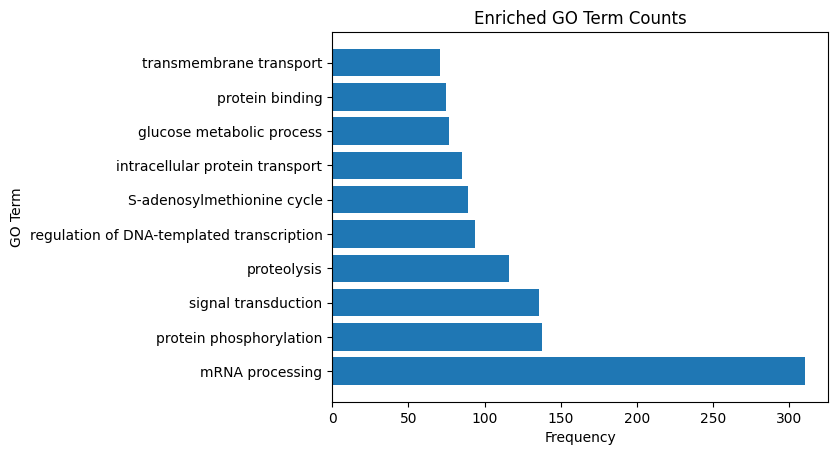

In [97]:
plot_goterms(counts_test)

In [99]:
chrs = ["chr1", "chr2", "chr3", "chr4", "chr5", "chr6", "chr7", "chr8", "chr9", "chr10", "chr11", "chr12", "chr13", "chr14", "chr15", 
        "chrUn1", "chrUn2", "chrUn3", "chrUn4", "chrUn5", "chrUn6", "chrUn7", "chrUn8", "chrUn9", "chrUn10", "chrUn11", "chrUn12", "chrUn13", "chrUn14", "chrUn15"]
def find_goterms(motif, within=10000):
    """
    Function that puts it all together to find all of the GO terms associated with a motif. Here, this takes the motif as a string,
    gets the positions along a chromosome, finds the GO terms from that chromosome, and repeats across the entire genome.
    - motif: string representation of the motif, for which exact matches are found.
    """

    assert len(chrs) == len(genome)

    term_ids = {}
    term_names = {}

    for i in range(len(chrs)):
        assert genome[i].name == chrs[i]
        positions = find_motif_positions(motif, genome[i]) 

        current_ids, current_names = find_goterms_onechr(positions, chrs[i], within=within)
        for key in current_ids:
            if key in term_ids:
                term_ids[key] += current_ids[key]
            else:
                term_ids[key] = current_ids[key]

        for name in current_names:
            if name in term_names:
                term_names[name] += current_names[name]
            else:
                term_names[name] = current_names[name]

    return term_ids, term_names

In [100]:
full_ids, full_names = find_goterms("AATAAAAAAA", within=1000)
full_names

{'peroxisome': 46,
 'rRNA processing': 155,
 'amino acid metabolic process': 15,
 'protein phosphorylation': 1417,
 'DNA damage checkpoint signaling': 31,
 'protein folding': 62,
 'chitin binding': 6,
 'cytoplasm': 431,
 'G protein-coupled receptor signaling pathway': 199,
 'transmembrane transport': 964,
 'extracellular space': 120,
 'membrane': 628,
 'cytosol': 71,
 'RNA export from nucleus': 72,
 'small GTPase-mediated signal transduction': 82,
 'lipid homeostasis': 13,
 'synaptic vesicle': 9,
 'cellular response to calcium ion': 40,
 'ceramide metabolic process': 12,
 'anterior/posterior pattern specification': 8,
 'retrograde transport, vesicle recycling within Golgi': 26,
 'protein binding': 1188,
 'pyrimidine nucleotide-sugar transmembrane transport': 2,
 'protein homooligomerization': 28,
 'membrane coat': 28,
 'intracellular signal transduction': 162,
 'oxidoreductase activity': 137,
 'activation of GTPase activity': 40,
 'lysine biosynthetic process via aminoadipic acid': 1,


In [101]:
def as_dataframe(counts):
    """
    Takes a dictionary of counts obtained from finding GO terms and returns a dataframe of the names/ids and respective counts.
    """
    name_list = list(counts)
    vals = [counts[n] for n in name_list]
    counts_df = pd.DataFrame({"name": name_list, "count": vals})
    return counts_df

full_df_test = as_dataframe(full_names)
full_df_test.head()

,name,count
0,peroxisome,46
1,rRNA processing,155
2,amino acid metabolic process,15
3,protein phosphorylation,1417
4,DNA damage checkpoint signaling,31


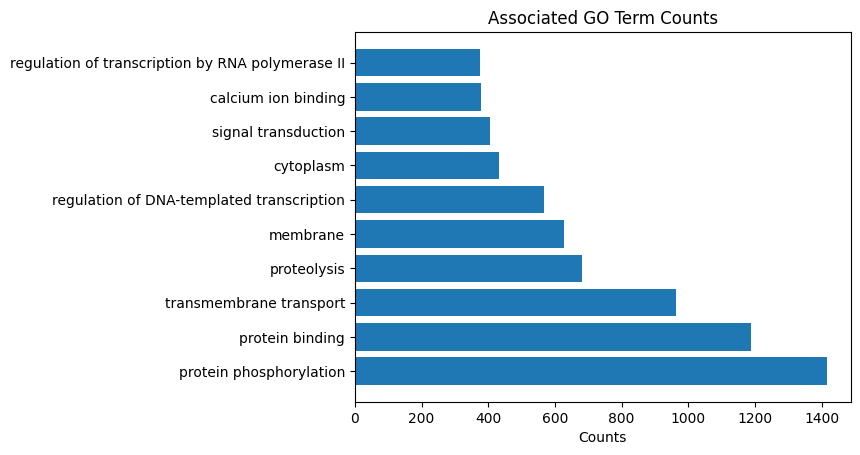

In [104]:
def plot_goterms(counts, n=10):
    """
    Takes a dataframe of counts, which can be obtained by as_dataframe(), and makes a horizontal barplot
    of the counts for the top n GO terms.
    - n (default 10): number of GO terms to display.
    """
    #does not assume counts are sorted; sorts them if so
    counts_sorted = counts.sort_values(by=["count"], ascending=False)
    counts_subframe = counts_sorted[0:n]

    plt.barh(counts_subframe['name'], counts_subframe["count"])
    plt.title('Associated GO Term Counts')
    #plt.ylabel('GO Term')
    plt.xlabel('Counts')
    plt.show()

plot_goterms(full_df_test)